In [7]:
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from pathlib import Path

In [26]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)


In [9]:
population_file = RAW_DATA_DIR / "ghana_population_by_geographic_area_2021.csv"

population_df = pd.read_csv(population_file)

In [10]:
# Define Ghana's 16 administrative regions
ghana_regions = [
    "Western",
    "Central",
    "Greater Accra",
    "Volta",
    "Eastern",
    "Ashanti",
    "Western North",
    "Ahafo",
    "Bono",
    "Bono East",
    "Oti",
    "Northern",
    "Savannah",
    "North East",
    "Upper East",
    "Upper West"
]

# Extract regional population records
regional_population = population_df[
    population_df["region"].isin(ghana_regions)
].copy()

# Display regional population records
display(regional_population)

# Calculate the number of regions
print("Number of regions:", regional_population["region"].nunique())

# Calculate combined regional population
print(
    "Combined regional population:",
    f"{regional_population['population'].sum():,}"
)

,region,population
1,Western,2060585
19,Central,2859821
44,Greater Accra,5455692
79,Volta,1659040
98,Eastern,2925653
132,Ashanti,5440463
181,Western North,880921
191,Ahafo,564668
198,Bono,1208649
211,Bono East,1203400


Number of regions: 16
Combined regional population: 30,832,019


In [11]:
# Retrieve Ghana's national population
ghana_total = population_df.loc[
    population_df["region"] == "Ghana",
    "population"
].iloc[0]


# Create a separate dataset for regional analysis
regional_analysis = regional_population.copy()


# Calculate each region's share of the national population
regional_analysis["population_share (%)"] = (
    regional_analysis["population"] / ghana_total * 100
).round(2)


# Rank regions from highest to lowest population
regional_analysis = regional_analysis.sort_values(
    by="population",
    ascending=False
).reset_index(drop=True)


# Assign population ranking
regional_analysis.insert(
    0,
    "rank",
    range(1, len(regional_analysis) + 1)
)


# Display regional population ranking
display(regional_analysis)


# Validate regional population totals
print("GHANA POPULATION VALIDATION")
print("-" * 45)

print(f"National population: {ghana_total:,}")

print(
    f"Combined regional population: "
    f"{regional_analysis['population'].sum():,}"
)

print(
    f"Difference: "
    f"{ghana_total - regional_analysis['population'].sum():,}"
)

,rank,region,population,population_share (%)
0,1,Greater Accra,5455692,17.69
1,2,Ashanti,5440463,17.65
2,3,Eastern,2925653,9.49
3,4,Central,2859821,9.28
4,5,Northern,2310928,7.50
5,6,Western,2060585,6.68
6,7,Volta,1659040,5.38
7,8,Upper East,1301226,4.22
8,9,Bono,1208649,3.92
9,10,Bono East,1203400,3.90


GHANA POPULATION VALIDATION
---------------------------------------------
National population: 30,832,019
Combined regional population: 30,832,019
Difference: 0


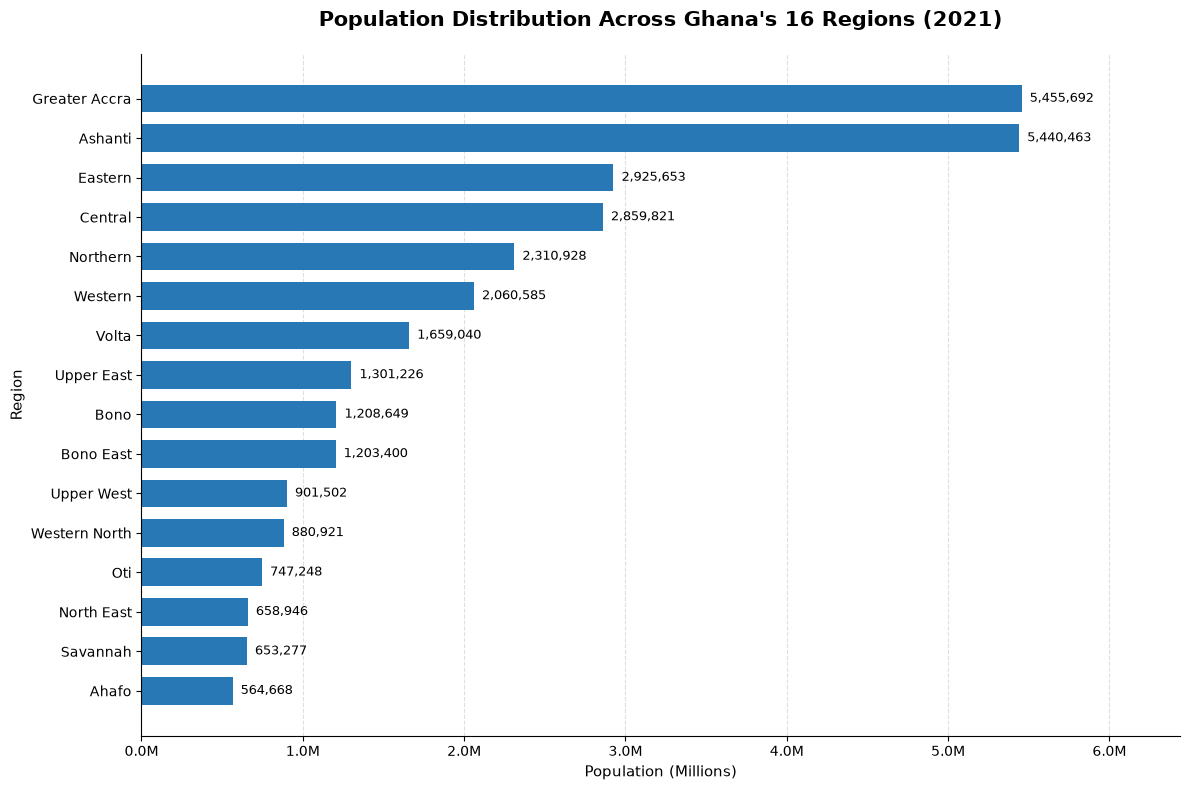

In [12]:
# Prepare chart data in ascending population order
chart_data = regional_analysis.sort_values(
    by="population",
    ascending=True
)

# Create figure and axis
fig, ax = plt.subplots(figsize=(12, 8))

# Create horizontal bar chart
bars = ax.barh(
    chart_data["region"],
    chart_data["population"],
    color="#2878B5",
    height=0.7
)

# Format horizontal axis in millions
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)

# Add population labels beside each bar
for bar in bars:

    width = bar.get_width()

    ax.text(
        width + 50000,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        fontsize=9
    )

# Chart title
ax.set_title(
    "Population Distribution Across Ghana's 16 Regions (2021)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# Axis labels
ax.set_xlabel("Population (Millions)", fontsize=11)
ax.set_ylabel("Region", fontsize=11)

# Improve chart appearance
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Create space for population labels
ax.set_xlim(
    0,
    chart_data["population"].max() * 1.18
)

plt.tight_layout()

In [27]:
# Define project output directory
output_dir = PROJECT_ROOT / "outputs" / "charts"

# Create directory if it does not exist
output_dir.mkdir(parents=True, exist_ok=True)

# Define output file
save_file_path = (
    output_dir / "regional_population_distribution.png"
)

# Save the specific figure
fig.savefig(
    save_file_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Display chart
plt.show()

# Confirm saved file
print("Chart saved successfully!")
print("File size:", f"{save_file_path.stat().st_size:,} bytes")

Chart saved successfully!
File size: 114,107 bytes


In [17]:
# Identify the most populated region
most_populated = regional_analysis.loc[
    regional_analysis["population"].idxmax()
]

# Identify the least populated region
least_populated = regional_analysis.loc[
    regional_analysis["population"].idxmin()
]

# Calculate population difference
population_difference = (
    most_populated["population"] -
    least_populated["population"]
)

# Display findings
print("=" * 60)
print("GHANA REGIONAL POPULATION ANALYSIS (2021)")
print("=" * 60)

print("\nMOST POPULATED REGION")
print("-" * 60)
print(f"Region: {most_populated['region']}")
print(f"Population: {most_populated['population']:,}")
print(f"National population share: {most_populated['population_share (%)']}%")

print("\nLEAST POPULATED REGION")
print("-" * 60)
print(f"Region: {least_populated['region']}")
print(f"Population: {least_populated['population']:,}")
print(f"National population share: {least_populated['population_share (%)']}%")

print("\nPOPULATION DIFFERENCE")
print("-" * 60)
print(f"Difference: {population_difference:,} people")

print("=" * 60)

GHANA REGIONAL POPULATION ANALYSIS (2021)

MOST POPULATED REGION
------------------------------------------------------------
Region: Greater Accra
Population: 5,455,692
National population share: 17.69%

LEAST POPULATED REGION
------------------------------------------------------------
Region: Ahafo
Population: 564,668
National population share: 1.83%

POPULATION DIFFERENCE
------------------------------------------------------------
Difference: 4,891,024 people


In [18]:
# Rank regions by population share
regional_share_ranking = regional_analysis.sort_values(
    by="population_share (%)",
    ascending=False
)

# Display top five regions by population share
print("TOP 5 REGIONS BY NATIONAL POPULATION SHARE")
print("-" * 60)

display(
    regional_share_ranking[
        ["region", "population", "population_share (%)"]
    ].head(5)
)

# Display bottom five regions by population share
print("BOTTOM 5 REGIONS BY NATIONAL POPULATION SHARE")
print("-" * 60)

display(
    regional_share_ranking[
        ["region", "population", "population_share (%)"]
    ].tail(5).sort_values(
        by="population_share (%)",
        ascending=True
    )
)

TOP 5 REGIONS BY NATIONAL POPULATION SHARE
------------------------------------------------------------


,region,population,population_share (%)
0,Greater Accra,5455692,17.69
1,Ashanti,5440463,17.65
2,Eastern,2925653,9.49
3,Central,2859821,9.28
4,Northern,2310928,7.50


BOTTOM 5 REGIONS BY NATIONAL POPULATION SHARE
------------------------------------------------------------


,region,population,population_share (%)
15,Ahafo,564668,1.83
14,Savannah,653277,2.12
13,North East,658946,2.14
12,Oti,747248,2.42
11,Western North,880921,2.86


In [19]:
# Population Concentration Analysis

print("=" * 65)
print("          GHANA POPULATION CONCENTRATION ANALYSIS")
print("=" * 65)

print(f"\nNational Population: {ghana_total:,}")

print("\nPOPULATION CONCENTRATION BY TOP REGIONS")
print("-" * 65)

# Analyse the top 3, 5 and 10 regions
for n in [3, 5, 10]:

    top_regions = regional_analysis.head(n)

    total_population = top_regions["population"].sum()

    population_share = (
        total_population / ghana_total
    ) * 100

    print(f"\nTOP {n} REGIONS")
    print("-" * 30)

    print(f"Combined Population : {total_population:,}")
    print(f"Population Share    : {population_share:.2f}%")

    print("\nRegions included:")

    for _, row in top_regions.iterrows():
        print(
            f"  {row['rank']:>2}. {row['region']:<18} "
            f"{row['population']:>12,}"
        )

print("\n" + "=" * 65)
print("END OF ANALYSIS")
print("=" * 65)

          GHANA POPULATION CONCENTRATION ANALYSIS

National Population: 30,832,019

POPULATION CONCENTRATION BY TOP REGIONS
-----------------------------------------------------------------

TOP 3 REGIONS
------------------------------
Combined Population : 13,821,808
Population Share    : 44.83%

Regions included:
   1. Greater Accra         5,455,692
   2. Ashanti               5,440,463
   3. Eastern               2,925,653

TOP 5 REGIONS
------------------------------
Combined Population : 18,992,557
Population Share    : 61.60%

Regions included:
   1. Greater Accra         5,455,692
   2. Ashanti               5,440,463
   3. Eastern               2,925,653
   4. Central               2,859,821
   5. Northern              2,310,928

TOP 10 REGIONS
------------------------------
Combined Population : 26,425,457
Population Share    : 85.71%

Regions included:
   1. Greater Accra         5,455,692
   2. Ashanti               5,440,463
   3. Eastern               2,925,653
   4. Cent

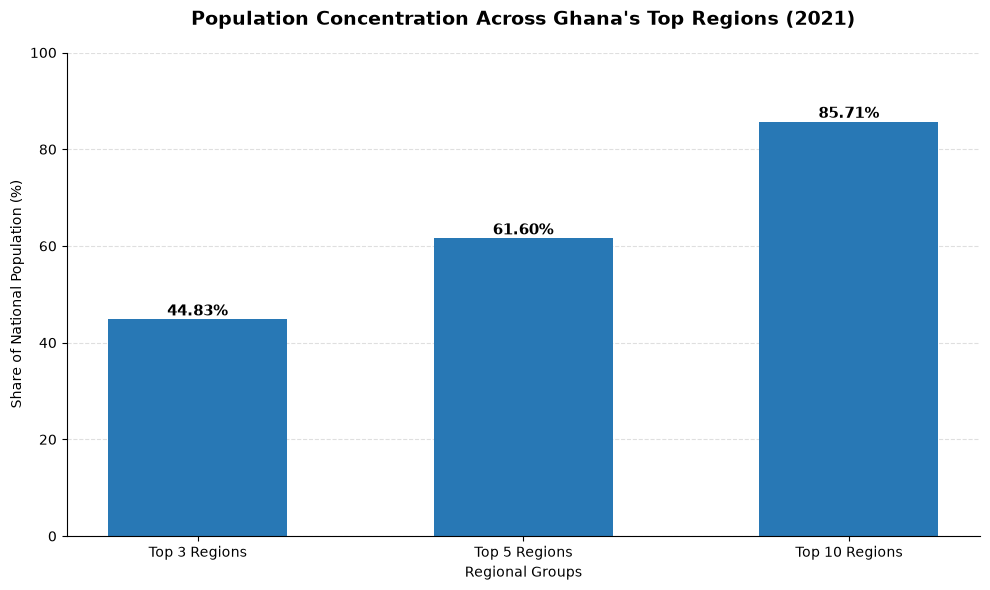

In [28]:
# Population concentration chart

concentration_data = []

for n in [3, 5, 10]:

    total_population = (
        regional_analysis.head(n)["population"].sum()
    )

    population_share = (
        total_population / ghana_total
    ) * 100

    concentration_data.append({
        "group": f"Top {n} Regions",
        "population_share": population_share
    })

# Convert results into a DataFrame
concentration_df = pd.DataFrame(concentration_data)

# Create chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    concentration_df["group"],
    concentration_df["population_share"],
    color="#2878B5",
    width=0.55
)

# Add percentage labels
for bar in bars:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.8,
        f"{height:.2f}%",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Population Concentration Across Ghana's Top Regions (2021)",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Regional Groups")
ax.set_ylabel("Share of National Population (%)")

ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save chart
save_file_path = output_dir / "population_concentration.png"

fig.savefig(
    save_file_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



In [24]:
print("=" * 55)
print("       POPULATION CONCENTRATION SUMMARY")
print("=" * 55)

for _, row in concentration_df.iterrows():

    print(
        f"{row['group']:<18} : "
        f"{row['population_share']:>6.2f}%"
    )

print("=" * 55)

       POPULATION CONCENTRATION SUMMARY
Top 3 Regions      :  44.83%
Top 5 Regions      :  61.60%
Top 10 Regions     :  85.71%
